In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV

In [2]:
# Load the data

In [3]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 1:]

In [4]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [5]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FPS                      10332 non-null  float64
 1   Frame Duration (ms)      10332 non-null  float64
 2   Min Frame Duration (ms)  10332 non-null  float64
 3   Max Frame Duration (ms)  10332 non-null  float64
 4   Avg Frame Duration (ms)  10332 non-null  float64
 5   Std Dev (ms)             10332 non-null  float64
 6   Entropy Framerate        10332 non-null  float64
 7   MotionToPhotonLatency    10332 non-null  float64
 8   minMtpLatency            10332 non-null  float64
 9   maxMtpLatency            10332 non-null  float64
 10  avgMtpLatency            10332 non-null  float64
 11  StdDev mtpLatency        10332 non-null  float64
 12  mtpEntropy               10332 non-null  float64
 13  currentRotation.x        10332 non-null  float64
 14  currentRotation.y     

In [6]:
Data.head(10)

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
5,77.87,12.84,12.65,16.11,13.26,1.50,0.09,12.84,12.84,14.34,14.32,4.70,0.14,0.34,-0.10,-0.14,0.93,36.49,339.33,336.17
6,69.38,14.41,12.65,14.52,13.88,0.88,0.31,14.41,12.84,14.41,14.37,4.71,0.15,0.33,-0.11,-0.14,0.93,36.22,339.10,336.32
7,68.05,14.69,12.65,14.69,14.28,1.12,0.41,14.69,14.41,14.69,14.53,4.70,0.19,0.33,-0.11,-0.14,0.93,35.86,338.75,336.44
8,69.73,14.34,12.65,14.69,14.31,1.01,0.30,14.34,14.34,14.69,14.45,0.65,0.18,0.33,-0.11,-0.13,0.93,35.46,338.31,336.46
9,80.83,12.37,12.37,14.69,13.51,0.90,0.07,12.37,12.37,14.34,13.60,0.94,0.20,0.33,-0.12,-0.13,0.93,35.04,337.75,336.37


In [7]:
Data.shape

(10332, 20)

In [8]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [9]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,...,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71,0
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,...,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73,0
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,...,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75,0
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,...,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85,0
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,...,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,...,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87,1
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,...,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15,1
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,...,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37,1
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,...,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80,1


In [10]:
# Select input features and target variable

In [11]:
X = Data.iloc[:, :-1]
#X.drop(['FPS'], axis=1, inplace=True)

In [12]:
y = Data['Labels']

In [13]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
# Fit a random forest classifier and get the feature importances
rfc = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rfc.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [16]:
print(f'model score on training data: {rfc.score(X_train, y_train)}')
print(f'model score on testing data: {rfc.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 1.0


In [17]:
importances_rfc = rfc.feature_importances_
indices = np.argsort(importances_rfc)[::-1]

In [18]:
# Get feature names
feature_names_rfc = X.columns

In [19]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances_rfc[indices[f]], feature_names_rfc[indices[f]]))

Feature ranking:
1. feature 0 (0.275368) - FPS
2. feature 1 (0.241241) - Frame Duration (ms)
3. feature 3 (0.110275) - Max Frame Duration (ms)
4. feature 7 (0.093187) - MotionToPhotonLatency
5. feature 10 (0.063665) - avgMtpLatency
6. feature 4 (0.055946) - Avg Frame Duration (ms)
7. feature 2 (0.054845) - Min Frame Duration (ms)
8. feature 5 (0.045891) - Std Dev (ms)
9. feature 8 (0.034316) - minMtpLatency
10. feature 9 (0.016962) - maxMtpLatency
11. feature 12 (0.002290) - mtpEntropy
12. feature 14 (0.001703) - currentRotation.y
13. feature 18 (0.001423) - yaw
14. feature 13 (0.000915) - currentRotation.x
15. feature 17 (0.000528) - pitch
16. feature 11 (0.000522) - StdDev mtpLatency
17. feature 6 (0.000374) - Entropy Framerate
18. feature 15 (0.000326) - currentRotation.z
19. feature 19 (0.000190) - roll
20. feature 16 (0.000035) - currentRotation.w


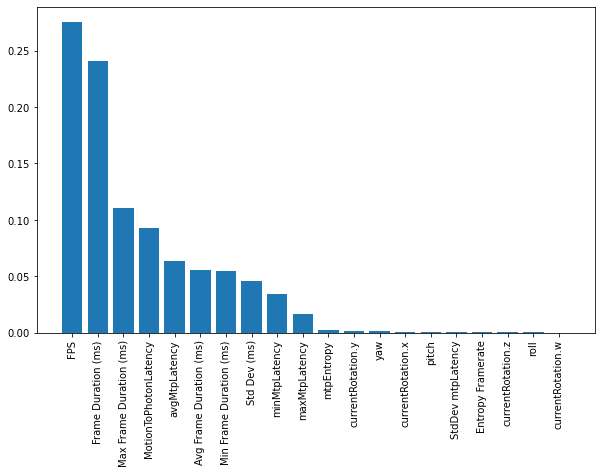

In [20]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances_rfc)), importances_rfc[indices])
plt.xticks(range(len(importances_rfc)), feature_names_rfc[indices], rotation=90)
plt.show()

In [21]:
# Calculate permutation importances
result = permutation_importance(rfc, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

In [22]:
# Print feature ranking
sorted_idx = result.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result.importances_mean[i]:.3f}) +/- {result.importances_std[i]}")

FPS             0.056) +/- 0.004169890997922874
Frame Duration (ms) 0.006) +/- 0.0007192099055306864
yaw             0.000) +/- 0.0
Min Frame Duration (ms) 0.000) +/- 0.0
Max Frame Duration (ms) 0.000) +/- 0.0
Avg Frame Duration (ms) 0.000) +/- 0.0
Std Dev (ms)    0.000) +/- 0.0
Entropy Framerate 0.000) +/- 0.0
MotionToPhotonLatency 0.000) +/- 0.0
minMtpLatency   0.000) +/- 0.0
roll            0.000) +/- 0.0
avgMtpLatency   0.000) +/- 0.0
StdDev mtpLatency 0.000) +/- 0.0
mtpEntropy      0.000) +/- 0.0
currentRotation.x 0.000) +/- 0.0
currentRotation.y 0.000) +/- 0.0
currentRotation.z 0.000) +/- 0.0
currentRotation.w 0.000) +/- 0.0
pitch           0.000) +/- 0.0
maxMtpLatency   0.000) +/- 0.0


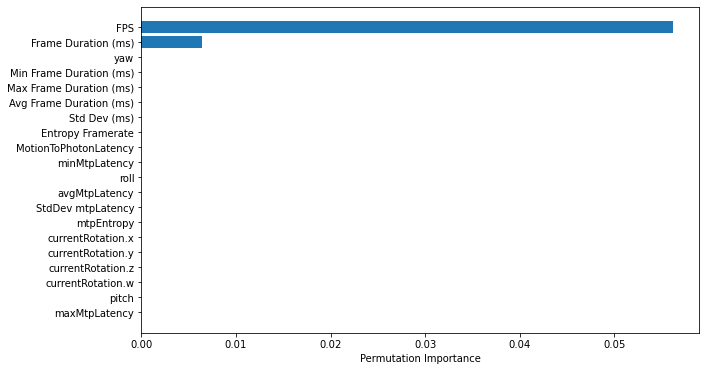

In [23]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [24]:
# Fit a random forest regressor and get the feature importances

In [25]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [26]:
print(f'model score on training data: {rf.score(X_train, y_train)}')
print(f'model score on testing data: {rf.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 0.9999977829738398


In [27]:
importances_rf = rf.feature_importances_
indices = np.argsort(importances_rf)[::-1]

In [28]:
# Get feature names
feature_names_rf = X.columns

In [29]:
# Sort features by importance
indices = np.argsort(importances_rf)[::-1]

In [30]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances_rf[indices[f]], feature_names_rf[indices[f]]))

Feature ranking:
1. feature 1 (0.550000) - Frame Duration (ms)
2. feature 0 (0.450000) - FPS
3. feature 18 (0.000000) - yaw
4. feature 2 (0.000000) - Min Frame Duration (ms)
5. feature 3 (0.000000) - Max Frame Duration (ms)
6. feature 4 (0.000000) - Avg Frame Duration (ms)
7. feature 5 (0.000000) - Std Dev (ms)
8. feature 6 (0.000000) - Entropy Framerate
9. feature 7 (0.000000) - MotionToPhotonLatency
10. feature 8 (0.000000) - minMtpLatency
11. feature 19 (0.000000) - roll
12. feature 10 (0.000000) - avgMtpLatency
13. feature 11 (0.000000) - StdDev mtpLatency
14. feature 12 (0.000000) - mtpEntropy
15. feature 13 (0.000000) - currentRotation.x
16. feature 14 (0.000000) - currentRotation.y
17. feature 15 (0.000000) - currentRotation.z
18. feature 16 (0.000000) - currentRotation.w
19. feature 17 (0.000000) - pitch
20. feature 9 (0.000000) - maxMtpLatency


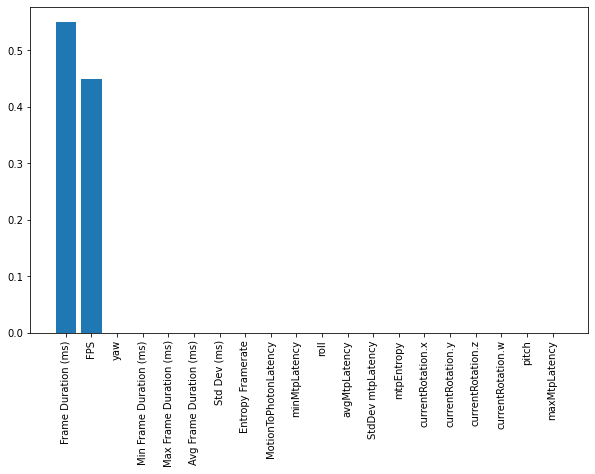

In [31]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances_rf)), importances_rf[indices])
plt.xticks(range(len(importances_rf)), feature_names_rf[indices], rotation=90)
plt.show()

In [32]:
# Calculate permutation importances

In [33]:
result = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

In [34]:
# Print feature ranking
sorted_idx = result.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result.importances_mean[i]:.3f} +/- {result.importances_std[i]:.3f}")

Frame Duration (ms) 0.608 +/- 0.012
FPS             0.407 +/- 0.008
yaw             0.000 +/- 0.000
Min Frame Duration (ms) 0.000 +/- 0.000
Max Frame Duration (ms) 0.000 +/- 0.000
Avg Frame Duration (ms) 0.000 +/- 0.000
Std Dev (ms)    0.000 +/- 0.000
Entropy Framerate 0.000 +/- 0.000
MotionToPhotonLatency 0.000 +/- 0.000
minMtpLatency   0.000 +/- 0.000
roll            0.000 +/- 0.000
avgMtpLatency   0.000 +/- 0.000
StdDev mtpLatency 0.000 +/- 0.000
mtpEntropy      0.000 +/- 0.000
currentRotation.x 0.000 +/- 0.000
currentRotation.y 0.000 +/- 0.000
currentRotation.z 0.000 +/- 0.000
currentRotation.w 0.000 +/- 0.000
pitch           0.000 +/- 0.000
maxMtpLatency   0.000 +/- 0.000


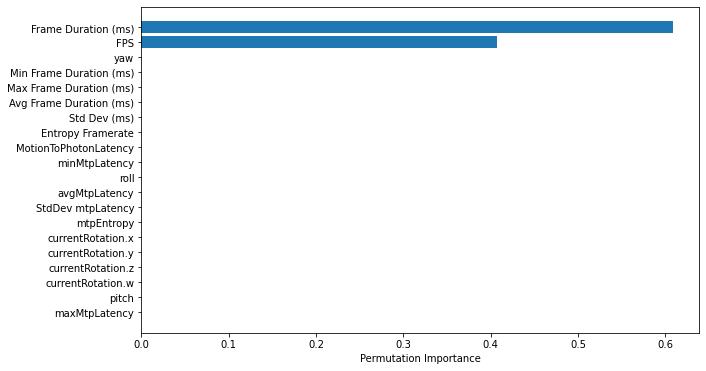

In [35]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [36]:
# Fit a linear regression model

In [37]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [38]:
print(f'model score on training data: {lr.score(X_train, y_train)}')
print(f'model score on testing data: {lr.score(X_test, y_test)}')

model score on training data: 0.8497021372115915
model score on testing data: 0.8508582533816352


In [39]:
# Get the coefficient values and feature names

In [40]:
coef_lr = lr.coef_

In [41]:
# Print the feature importance

In [42]:
feature_names_lr = X.columns

In [43]:
# Print the feature importance
print("Feature importance:")
for i in range(len(feature_names_lr)):
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
FPS: 0.418359
Frame Duration (ms): 0.063737
Min Frame Duration (ms): 0.016698
Max Frame Duration (ms): 0.004040
Avg Frame Duration (ms): 0.208651
Std Dev (ms): 0.006016
Entropy Framerate: 0.018153
MotionToPhotonLatency: 0.000486
minMtpLatency: 0.029138
maxMtpLatency: 0.021822
avgMtpLatency: 0.244501
StdDev mtpLatency: 0.004521
mtpEntropy: 0.010851
currentRotation.x: 0.008405
currentRotation.y: 0.038465
currentRotation.z: 0.026352
currentRotation.w: 0.001047
pitch: 0.001848
yaw: 0.013865
roll: 0.002291


In [44]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
FPS: 0.418359
avgMtpLatency: 0.244501
Avg Frame Duration (ms): 0.208651
Frame Duration (ms): 0.063737
currentRotation.y: 0.038465
minMtpLatency: 0.029138
currentRotation.z: 0.026352
maxMtpLatency: 0.021822
Entropy Framerate: 0.018153
Min Frame Duration (ms): 0.016698
yaw: 0.013865
mtpEntropy: 0.010851
currentRotation.x: 0.008405
Std Dev (ms): 0.006016
StdDev mtpLatency: 0.004521
Max Frame Duration (ms): 0.004040
roll: 0.002291
pitch: 0.001848
currentRotation.w: 0.001047
MotionToPhotonLatency: 0.000486


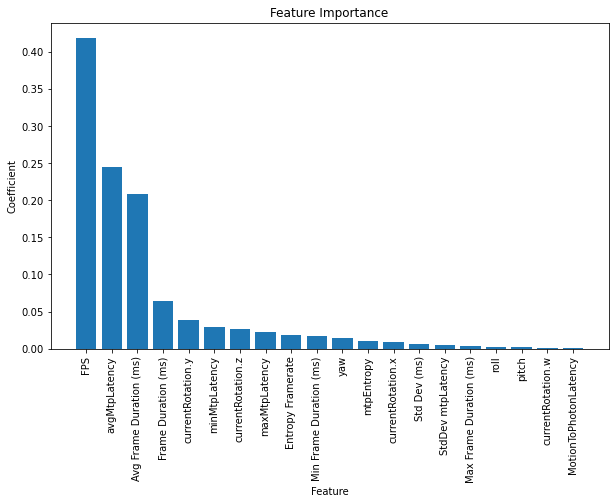

In [45]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names_lr[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [46]:
# Calculate permutation importances

In [47]:
result = permutation_importance(lr, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

In [48]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lr[i], result.importances_mean[i]))

Permutation importances:
FPS: 1.568610
avgMtpLatency: 0.536567
Avg Frame Duration (ms): 0.409976
Frame Duration (ms): 0.030895
currentRotation.y: 0.014700
minMtpLatency: 0.008973
currentRotation.z: 0.004967
Min Frame Duration (ms): 0.003457
Entropy Framerate: 0.002505
yaw: 0.001069
StdDev mtpLatency: 0.000778
currentRotation.x: 0.000751
mtpEntropy: 0.000445
maxMtpLatency: 0.000190
currentRotation.w: 0.000068
MotionToPhotonLatency: 0.000065
roll: 0.000052
pitch: -0.000011
Max Frame Duration (ms): -0.000354
Std Dev (ms): -0.000453


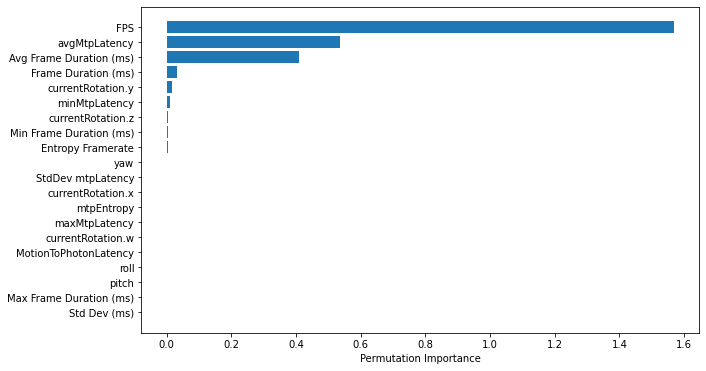

In [49]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [50]:
# Fit a Logistic Regression model

In [51]:
lor = LogisticRegression(max_iter= 1000)
lor.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [52]:
print(f'model score on training data: {lor.score(X_train, y_train)}')
print(f'model score on testing data: {lor.score(X_test, y_test)}')

model score on training data: 0.996854204476709
model score on testing data: 0.996129656507015


In [53]:
# Get the coefficient values and feature names

In [54]:
coef_lor = lor.coef_[0]
feature_names_lor = X.columns

In [55]:
# Print the feature names and their absolute coefficient values in descending order
for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1]):
    print("%s: %f" % (name, value))

FPS: 11.280200
Frame Duration (ms): 1.879237
Max Frame Duration (ms): 0.731208
Min Frame Duration (ms): 0.677098
minMtpLatency: 0.616412
avgMtpLatency: 0.530166
MotionToPhotonLatency: 0.492707
Std Dev (ms): 0.278169
mtpEntropy: 0.273858
Entropy Framerate: 0.273095
maxMtpLatency: 0.149060
currentRotation.x: 0.113061
StdDev mtpLatency: 0.094463
currentRotation.y: 0.086805
roll: 0.065025
yaw: 0.061817
Avg Frame Duration (ms): 0.042361
currentRotation.z: 0.041797
currentRotation.w: 0.016502
pitch: 0.010747


In [56]:
# Sort features by absolute coefficient value
sorted_features = [name for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]
sorted_coefs = [value for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]

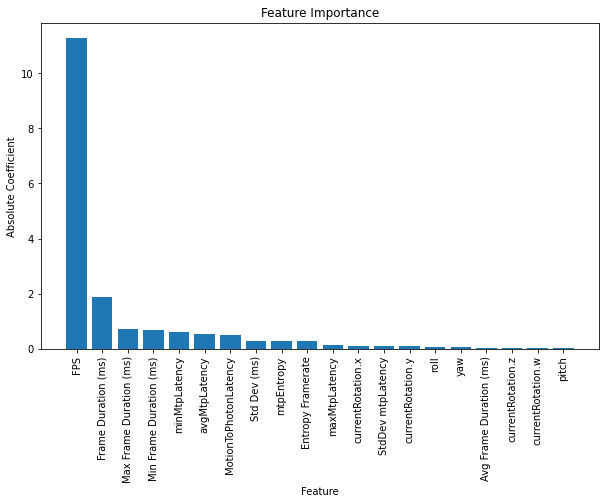

In [57]:
# Create bar plot of feature importance
plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefs)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Absolute Coefficient')
plt.title('Feature Importance')
plt.show()

In [58]:
# Calculate permutation importances

In [59]:
result = permutation_importance(lor, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

In [60]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lor[i], result.importances_mean[i]))

Permutation importances:
FPS: 0.403677
Frame Duration (ms): 0.006967
Min Frame Duration (ms): 0.001838
Entropy Framerate: 0.001790
Max Frame Duration (ms): 0.001403
MotionToPhotonLatency: 0.001016
minMtpLatency: 0.000726
mtpEntropy: 0.000629
currentRotation.x: 0.000581
currentRotation.w: 0.000339
currentRotation.y: 0.000290
Std Dev (ms): 0.000290
StdDev mtpLatency: 0.000242
maxMtpLatency: 0.000194
Avg Frame Duration (ms): 0.000145
currentRotation.z: 0.000097
pitch: 0.000048
roll: 0.000000
avgMtpLatency: -0.000097
yaw: -0.000097


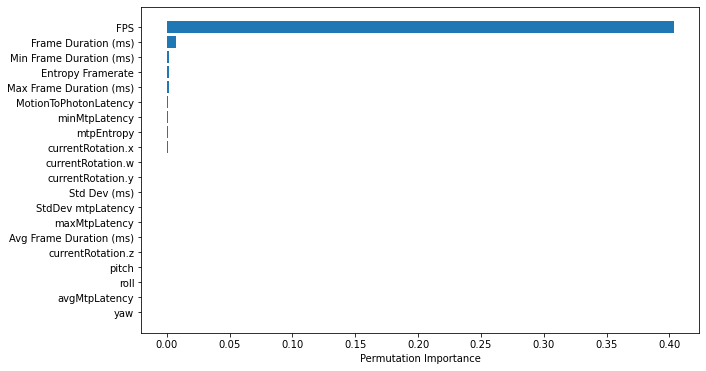

In [61]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [62]:
#Decision tree-based 

In [63]:
# Train a decision tree classifier on the original dataset

In [64]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [65]:
print(f'model score on training data: {clf.score(X_train, y_train)}')
print(f'model score on testing data: {clf.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 1.0


In [66]:
# Plot the feature importance

In [67]:
importance_clf = clf.feature_importances_
feature_names_clf = X.columns

In [68]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importance_clf})

In [69]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
1       Frame Duration (ms)         1.0
0                       FPS         0.0
18                      yaw         0.0
17                    pitch         0.0
16        currentRotation.w         0.0
15        currentRotation.z         0.0
14        currentRotation.y         0.0
13        currentRotation.x         0.0
12               mtpEntropy         0.0
11        StdDev mtpLatency         0.0
10            avgMtpLatency         0.0
9             maxMtpLatency         0.0
8             minMtpLatency         0.0
7     MotionToPhotonLatency         0.0
6         Entropy Framerate         0.0
5              Std Dev (ms)         0.0
4   Avg Frame Duration (ms)         0.0
3   Max Frame Duration (ms)         0.0
2   Min Frame Duration (ms)         0.0
19                     roll         0.0


In [70]:
sorted_idx = importance_clf.argsort()

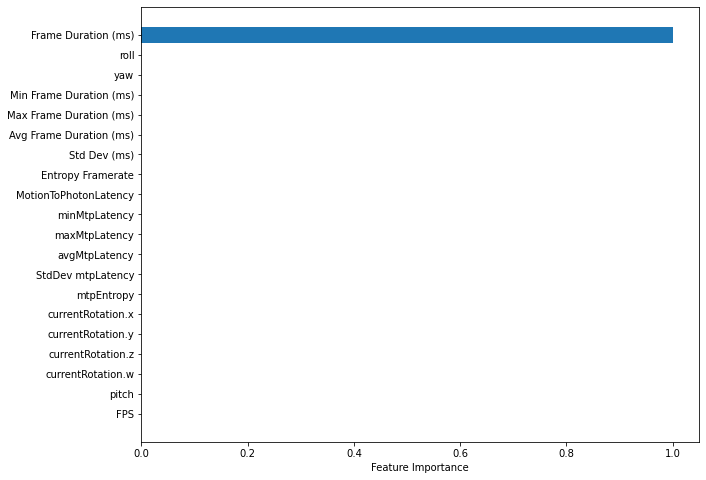

In [71]:
plt.figure(figsize = (10, 8))
plt.barh(range(len(sorted_idx)), importance_clf[sorted_idx])
plt.yticks(range(len(sorted_idx)), [feature_names_clf[i] for i in sorted_idx])
plt.xlabel('Feature Importance')
plt.show()

In [72]:
# Calculate permutation importance
perm_importance = permutation_importance(clf, X_train, y_train, n_repeats=10, random_state=42, n_jobs=-1)

In [73]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [74]:
feature_importance

,Feature,Importance
0,FPS,0.000000
1,Frame Duration (ms),0.438475
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.000000
9,maxMtpLatency,0.000000


In [75]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False, )
print(feature_importance)

                    Feature  Importance
1       Frame Duration (ms)    0.438475
0                       FPS    0.000000
18                      yaw    0.000000
17                    pitch    0.000000
16        currentRotation.w    0.000000
15        currentRotation.z    0.000000
14        currentRotation.y    0.000000
13        currentRotation.x    0.000000
12               mtpEntropy    0.000000
11        StdDev mtpLatency    0.000000
10            avgMtpLatency    0.000000
9             maxMtpLatency    0.000000
8             minMtpLatency    0.000000
7     MotionToPhotonLatency    0.000000
6         Entropy Framerate    0.000000
5              Std Dev (ms)    0.000000
4   Avg Frame Duration (ms)    0.000000
3   Max Frame Duration (ms)    0.000000
2   Min Frame Duration (ms)    0.000000
19                     roll    0.000000


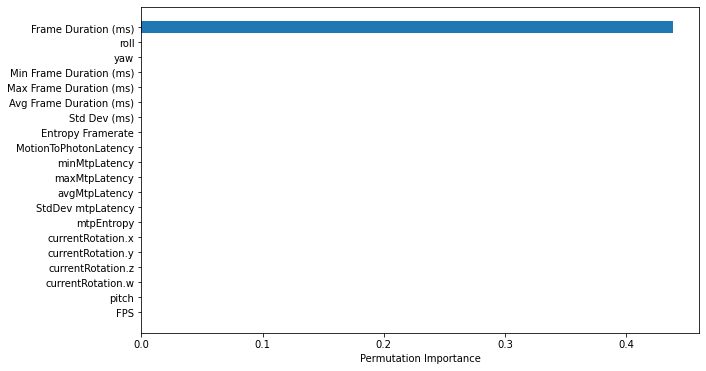

In [76]:
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), perm_importance.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [77]:
#Lasso regression

In [78]:
# Train a Lasso regression model on the original dataset

In [79]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [80]:
# Define the range of alpha values to search
alphas = np.logspace(-5, 2, 50)

# Define the parameters for Randomized Search
param_distributions = {
    'alpha': alphas
}

# Instantiate RandomizedSearchCV with Lasso, parameter grid, and cross-validation settings
randomized_search = RandomizedSearchCV(Lasso(), param_distributions, scoring='neg_mean_squared_error', cv=5, n_iter=20, random_state=42)

# Fit RandomizedSearchCV to the scaled data
randomized_search.fit(X_train_scaled, y_train)

# Get the best alpha value
best_alpha = randomized_search.best_params_['alpha']

print(f'Best alpha value: {best_alpha}')


Best alpha value: 0.00013894954943731373


In [81]:
Lasso = Lasso(alpha=best_alpha)
Lasso.fit(X_train_scaled, y_train)

Lasso(alpha=0.00013894954943731373)

In [82]:
print(f'model score on training data: {Lasso.score(X_train, y_train)}')
print(f'model score on testing data: {Lasso.score(X_test, y_test)}')

model score on training data: 0.8496467515889055
model score on testing data: 0.8512996575519787


In [83]:
# Get the absolute value of the regression coefficients

In [84]:
Lasso_abs = abs(Lasso.coef_)

In [85]:
Lasso_abs

array([0.41949322, 0.06405974, 0.01609496, 0.        , 0.17332107,
       0.00485166, 0.01706278, 0.        , 0.02717464, 0.02006596,
       0.20888854, 0.        , 0.0084514 , 0.0077902 , 0.03862445,
       0.02589876, 0.00108529, 0.00248611, 0.01353911, 0.00274914])

In [86]:
# Create a DataFrame to store the feature importance scores and names

In [87]:
feature_importance_Lasso = pd.DataFrame({'Feature_names': X.columns, 'Importance':Lasso_abs})

In [88]:
# Sort the features by importance and print the ranked list

In [89]:
feature_importance_Lasso = feature_importance_Lasso.sort_values('Importance', ascending=False)

In [90]:
feature_importance_Lasso

,Feature_names,Importance
0,FPS,0.419493
10,avgMtpLatency,0.208889
4,Avg Frame Duration (ms),0.173321
1,Frame Duration (ms),0.064060
14,currentRotation.y,0.038624
8,minMtpLatency,0.027175
15,currentRotation.z,0.025899
9,maxMtpLatency,0.020066
6,Entropy Framerate,0.017063
2,Min Frame Duration (ms),0.016095


In [91]:
# Create a barplot of the feature importance scores>

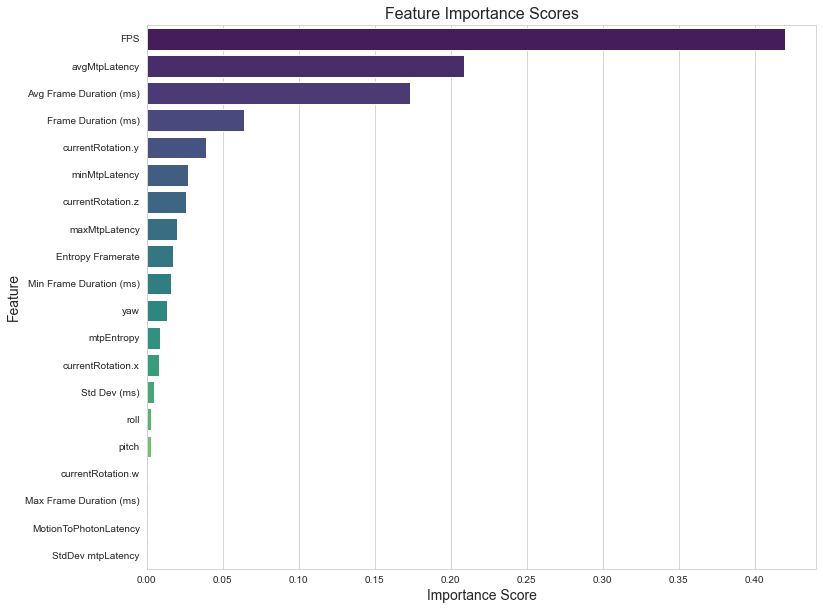

In [92]:
plt.figure(figsize=(12, 10))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance_Lasso, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [93]:
# Calculate permutation importance
perm_importance_Lasso = permutation_importance(Lasso, X_test_scaled, y_test, n_repeats=10, random_state=42)

In [94]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_Lasso.importances_mean})

In [95]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature    Importance
0                       FPS  1.577389e+00
10            avgMtpLatency  3.901103e-01
4   Avg Frame Duration (ms)  2.847503e-01
1       Frame Duration (ms)  3.128655e-02
14        currentRotation.y  1.492747e-02
8             minMtpLatency  8.060677e-03
15        currentRotation.z  4.781830e-03
2   Min Frame Duration (ms)  3.298798e-03
6         Entropy Framerate  2.260847e-03
18                      yaw  1.025984e-03
13        currentRotation.x  6.583451e-04
12               mtpEntropy  1.712999e-04
19                     roll  7.640218e-05
16        currentRotation.w  7.256775e-05
17                    pitch  7.230585e-07
3   Max Frame Duration (ms)  0.000000e+00
7     MotionToPhotonLatency  0.000000e+00
11        StdDev mtpLatency  0.000000e+00
9             maxMtpLatency -5.923310e-05
5              Std Dev (ms) -4.151918e-04


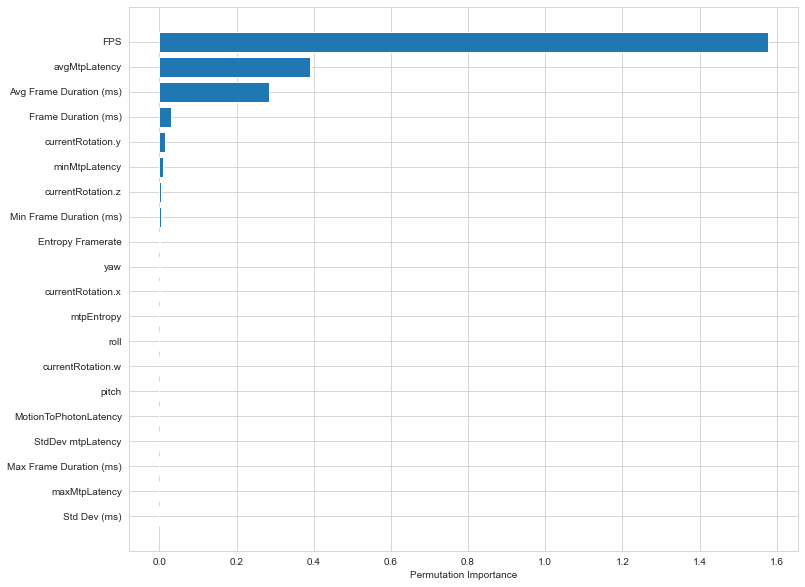

In [96]:
# Plot feature importances
plt.figure(figsize=(12, 10))
sorted_idx = perm_importance_Lasso.importances_mean.argsort()
plt.barh(range(X.shape[1]), perm_importance_Lasso.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [97]:
#XGBClassifier

In [98]:
from xgboost import XGBClassifier

In [99]:
# Instantiate XGBClassifier with default hyperparameters

In [100]:
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [101]:
# Use the built-in feature importance method to get feature importance scores
feat_importances_xgb = xgb.feature_importances_

In [102]:
feat_importances_xgb

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.], dtype=float32)

In [103]:
# Create a dictionary mapping feature names to importance scores
feat_importances_dict = {feat: score for feat, score in zip(X.columns, feat_importances_xgb)}

In [104]:
feat_importances_dict

{'FPS': 1.0,
 'Frame Duration (ms)': 0.0,
 'Min Frame Duration (ms)': 0.0,
 'Max Frame Duration (ms)': 0.0,
 'Avg Frame Duration (ms)': 0.0,
 'Std Dev (ms)': 0.0,
 'Entropy Framerate': 0.0,
 'MotionToPhotonLatency': 0.0,
 'minMtpLatency': 0.0,
 'maxMtpLatency': 0.0,
 'avgMtpLatency': 0.0,
 'StdDev mtpLatency': 0.0,
 'mtpEntropy': 0.0,
 'currentRotation.x': 0.0,
 'currentRotation.y': 0.0,
 'currentRotation.z': 0.0,
 'currentRotation.w': 0.0,
 'pitch': 0.0,
 'yaw': 0.0,
 'roll': 0.0}

In [105]:
# Sort the ditionary in descending order of importance score
sorted_feat_importances = sorted(feat_importances_dict.items(), key=lambda x: x[1], reverse=True)

In [106]:
# Print the sorted feature importance scores
for feat, score in sorted_feat_importances:
    print(f'{feat}: {score}')

FPS: 1.0
Frame Duration (ms): 0.0
Min Frame Duration (ms): 0.0
Max Frame Duration (ms): 0.0
Avg Frame Duration (ms): 0.0
Std Dev (ms): 0.0
Entropy Framerate: 0.0
MotionToPhotonLatency: 0.0
minMtpLatency: 0.0
maxMtpLatency: 0.0
avgMtpLatency: 0.0
StdDev mtpLatency: 0.0
mtpEntropy: 0.0
currentRotation.x: 0.0
currentRotation.y: 0.0
currentRotation.z: 0.0
currentRotation.w: 0.0
pitch: 0.0
yaw: 0.0
roll: 0.0


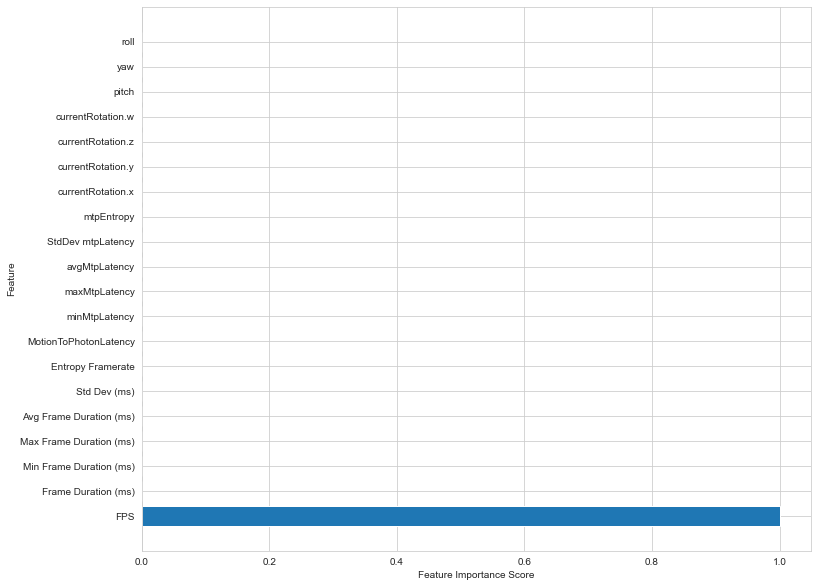

In [107]:
# Plot the feature importance scores as a horizontal bar chart
plt.figure(figsize = (12, 10))
plt.barh(range(len(feat_importances_xgb)), feat_importances_xgb)
plt.yticks(range(len(feat_importances_xgb)), X.columns)
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.show()

In [108]:
# Calculate permutation importance
perm_importance_xgb = permutation_importance(xgb, X_train, y_train, n_repeats=10, random_state=42)

In [109]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_xgb.importances_mean})

In [110]:
feature_importance 

,Feature,Importance
0,FPS,0.438475
1,Frame Duration (ms),0.000000
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.000000
9,maxMtpLatency,0.000000


In [111]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
0                       FPS    0.438475
1       Frame Duration (ms)    0.000000
18                      yaw    0.000000
17                    pitch    0.000000
16        currentRotation.w    0.000000
15        currentRotation.z    0.000000
14        currentRotation.y    0.000000
13        currentRotation.x    0.000000
12               mtpEntropy    0.000000
11        StdDev mtpLatency    0.000000
10            avgMtpLatency    0.000000
9             maxMtpLatency    0.000000
8             minMtpLatency    0.000000
7     MotionToPhotonLatency    0.000000
6         Entropy Framerate    0.000000
5              Std Dev (ms)    0.000000
4   Avg Frame Duration (ms)    0.000000
3   Max Frame Duration (ms)    0.000000
2   Min Frame Duration (ms)    0.000000
19                     roll    0.000000


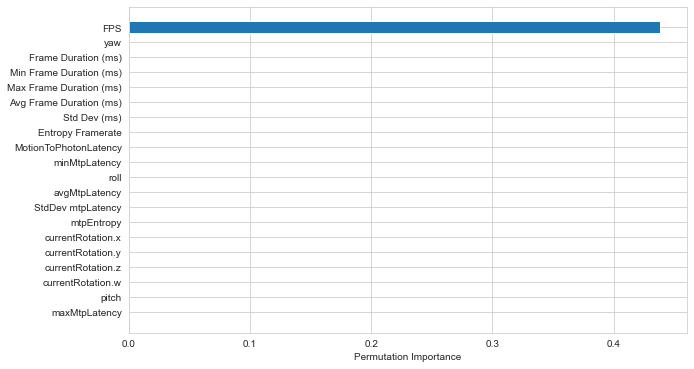

In [112]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_xgb.importances_mean.argsort()
plt.barh(range(X.shape[1]), perm_importance_xgb.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [113]:
#Elastic Net Feature Importance

In [114]:
from sklearn.linear_model import ElasticNetCV

# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=42)

# Fit the model on training data
enet.fit(X_train, y_train)

# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])


FPS :  0.4761731906350056
avgMtpLatency :  0.14813410054727374
Avg Frame Duration (ms) :  0.10814463236612605
Frame Duration (ms) :  0.0733645205726369
currentRotation.y :  0.04418668898027501
currentRotation.z :  0.02822185645479999
minMtpLatency :  0.025452920175946858
maxMtpLatency :  0.021435247323642756
Min Frame Duration (ms) :  0.018664300598080386
Entropy Framerate :  0.01711100588169066
yaw :  0.014440719340670677
currentRotation.x :  0.007210281649976083
pitch :  0.0045870587280928896
roll :  0.004366045823767929
mtpEntropy :  0.004302201284733375
StdDev mtpLatency :  0.0017618229099816826
currentRotation.w :  0.001331594468200558
Std Dev (ms) :  0.0011118122590987821
Max Frame Duration (ms) :  0.0
MotionToPhotonLatency :  0.0


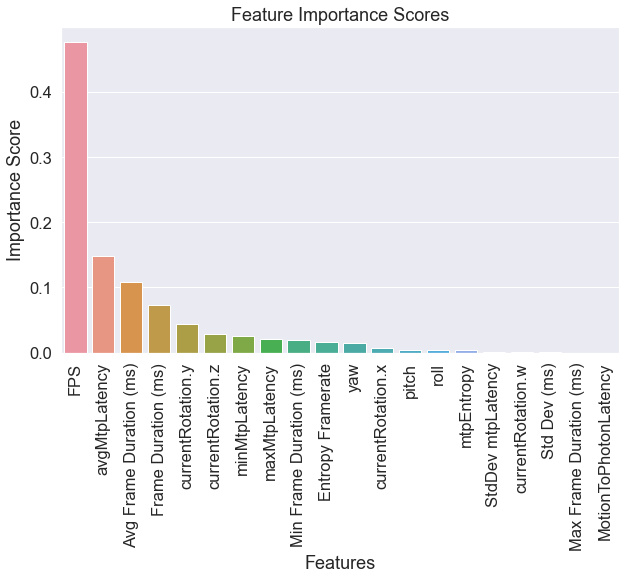

In [115]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [116]:
# Calculate permutation importance
perm_importance_enet = permutation_importance(enet, X_train, y_train, n_repeats=10, random_state=42)

In [117]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_enet = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_enet

,Feature,Importance
0,FPS,1.609940
1,Frame Duration (ms),0.038627
2,Min Frame Duration (ms),0.002612
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.083927
5,Std Dev (ms),0.000011
6,Entropy Framerate,0.002246
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.004542
9,maxMtpLatency,0.003391


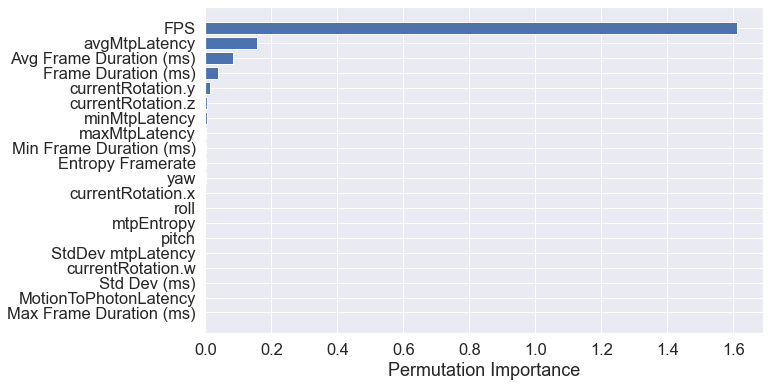

In [133]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), perm_importance_enet.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [119]:
# Ridge model

In [120]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [121]:
# Predict on the testing data
y_pred = ridge.predict(X_test)

In [122]:
from sklearn.metrics import mean_squared_error

In [123]:
# Evaluate the model performance on testing data
mse = mean_squared_error(y_test, y_pred)
print("Mean squared error:", mse)

Mean squared error: 0.0325255074235983


In [124]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [125]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [126]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [136]:
features_dict

{'FPS': 0.37159661500829916,
 'Frame Duration (ms)': 0.05674178147036781,
 'Min Frame Duration (ms)': 0.014889146992821204,
 'Max Frame Duration (ms)': 0.003293124469974733,
 'Avg Frame Duration (ms)': 0.17982432788295472,
 'Std Dev (ms)': 0.00528782608554899,
 'Entropy Framerate': 0.016003584703137154,
 'MotionToPhotonLatency': 0.00033590744290104107,
 'minMtpLatency': 0.02570207927696177,
 'maxMtpLatency': 0.019374033326468174,
 'avgMtpLatency': 0.21172542195918825,
 'StdDev mtpLatency': 0.003770971889804328,
 'mtpEntropy': 0.00936670812230237,
 'currentRotation.x': 0.0073837030723432045,
 'currentRotation.y': 0.0342178834767314,
 'currentRotation.z': 0.023379375752163225,
 'currentRotation.w': 0.0009505343035773856,
 'pitch': 0.0017598685972942,
 'yaw': 0.012275786322820248,
 'roll': 0.002121319844340329}

In [127]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [128]:
sorted_features

[('FPS', 0.37159661500829916),
 ('avgMtpLatency', 0.21172542195918825),
 ('Avg Frame Duration (ms)', 0.17982432788295472),
 ('Frame Duration (ms)', 0.05674178147036781),
 ('currentRotation.y', 0.0342178834767314),
 ('minMtpLatency', 0.02570207927696177),
 ('currentRotation.z', 0.023379375752163225),
 ('maxMtpLatency', 0.019374033326468174),
 ('Entropy Framerate', 0.016003584703137154),
 ('Min Frame Duration (ms)', 0.014889146992821204),
 ('yaw', 0.012275786322820248),
 ('mtpEntropy', 0.00936670812230237),
 ('currentRotation.x', 0.0073837030723432045),
 ('Std Dev (ms)', 0.00528782608554899),
 ('StdDev mtpLatency', 0.003770971889804328),
 ('Max Frame Duration (ms)', 0.003293124469974733),
 ('roll', 0.002121319844340329),
 ('pitch', 0.0017598685972942),
 ('currentRotation.w', 0.0009505343035773856),
 ('MotionToPhotonLatency', 0.00033590744290104107)]

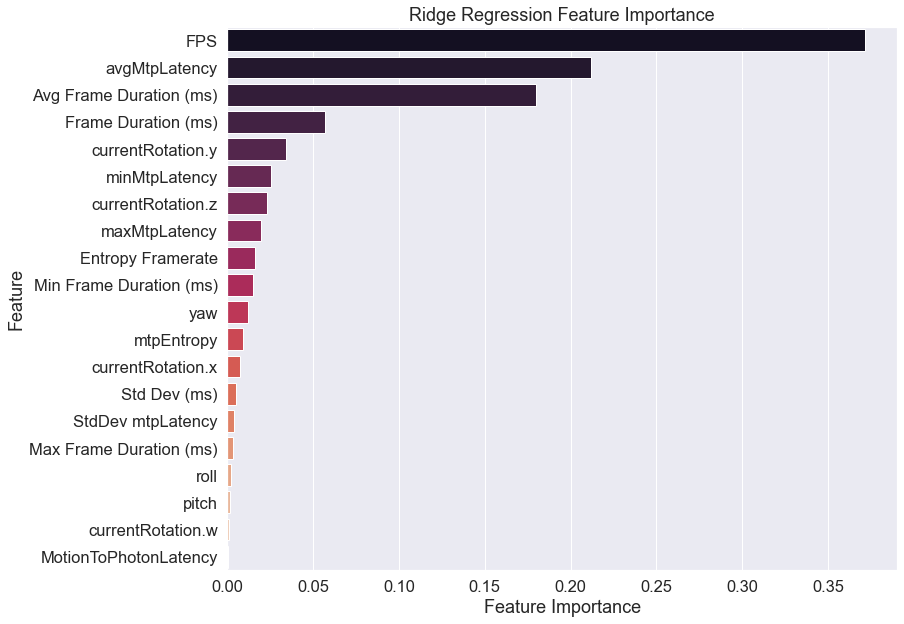

In [135]:
plt.figure(figsize=(12, 10))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [130]:
# Calculate permutation importance
perm_importance_ridge = permutation_importance(ridge, X_train, y_train, n_repeats=10, random_state=42)

In [131]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_ridge = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_ridge

,Feature,Importance
0,FPS,1.609940
1,Frame Duration (ms),0.038627
2,Min Frame Duration (ms),0.002612
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.083927
5,Std Dev (ms),0.000011
6,Entropy Framerate,0.002246
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.004542
9,maxMtpLatency,0.003391


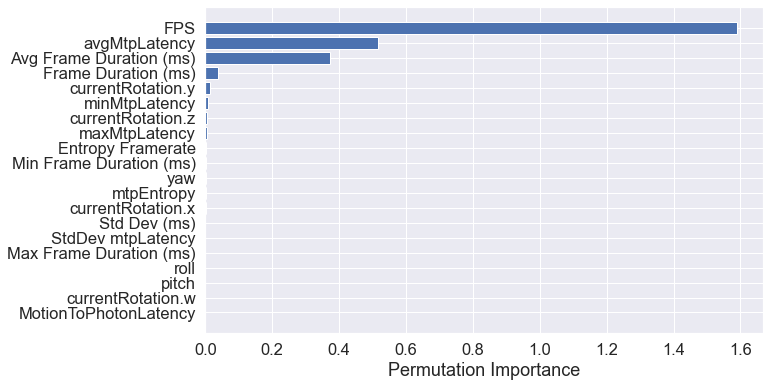

In [134]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), perm_importance_ridge.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()